Columns: ['date', 'jobcountry', 'indeed_job_postings_index', 'variable', 'display_name']
        date jobcountry  indeed_job_postings_index        variable  \
0 2020-02-01         US                     100.00  total postings   
1 2020-02-01         US                     100.00    new postings   
2 2020-02-02         US                     100.30  total postings   
3 2020-02-02         US                     100.60    new postings   
4 2020-02-03         US                     100.56  total postings   

  display_name  
0   Accounting  
1   Accounting  
2   Accounting  
3   Accounting  
4   Accounting   

Sector column: display_name
Value column:  indeed_job_postings_index
Sectors available: ['Accounting', 'Administrative Assistance', 'Architecture', 'Arts & Entertainment', 'Aviation', 'Banking & Finance', 'Childcare', 'Civil Engineering', 'Cleaning & Sanitation', 'Community & Social Service', 'Construction', 'Customer Service', 'Data & Analytics', 'Dental', 'Driving', 'Education & In

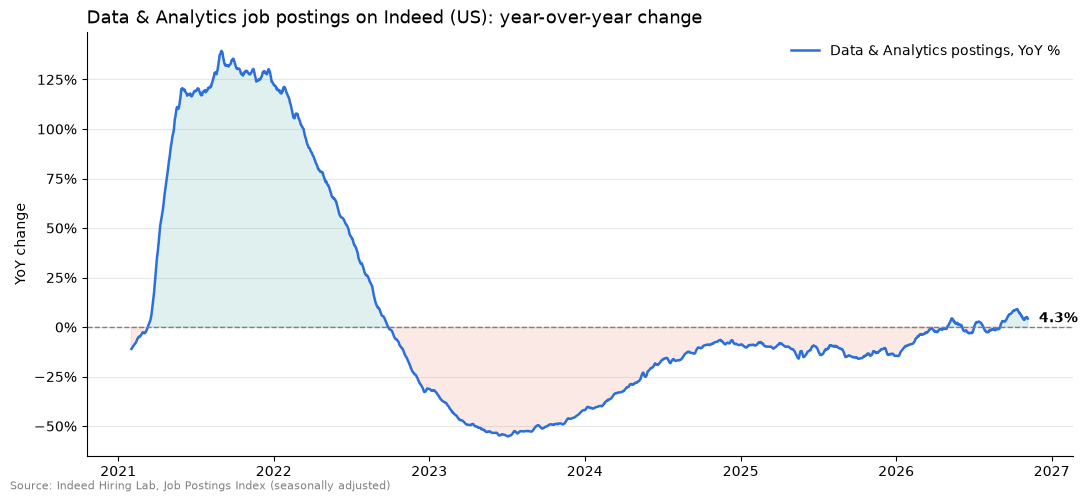

In [4]:
"""
YoY change in Indeed job postings for the Data & Analytics sector.

Usage:
    1. Put this script in the same folder as job_postings_by_sector_US.csv
       (or change FILE_PATH below).
    2. Run:  python data_analytics_yoy.py
"""

import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick

FILE_PATH = "job_postings_by_sector_US.csv"
SECTOR_KEYWORD = "data"          # matches "Data & Analytics"

# ---------------------------------------------------------------
# 1. Read the data
# ---------------------------------------------------------------
df = pd.read_csv(FILE_PATH, parse_dates=["date"])

print("Columns:", list(df.columns))
print(df.head(), "\n")

# Find the sector column and the index-value column automatically,
# so the script works even if Indeed renames them slightly.
text_cols = df.select_dtypes(exclude=["number", "datetime"]).columns.tolist()
sector_col = max(text_cols, key=lambda c: df[c].nunique())   # column with most categories
value_col = [c for c in df.columns if "index" in c.lower()][0]

print(f"Sector column: {sector_col}")
print(f"Value column:  {value_col}")
print("Sectors available:", sorted(df[sector_col].unique()), "\n")

# ---------------------------------------------------------------
# 2. Filter to Data & Analytics
# ---------------------------------------------------------------
da = df[df[sector_col] == "Data & Analytics"].copy()
print("Selected sector:", da[sector_col].unique())

# Some files hold several rows per date for one sector (e.g. a column
# that splits "total postings" vs "new postings"). Find any such column
# and keep a single row per date.
for col in da.select_dtypes(exclude=["number", "datetime"]).columns:
    if col == sector_col or da[col].nunique() <= 1:
        continue
    options = list(da[col].unique())
    keep = next((o for o in options if "total" in str(o).lower()), options[0])
    print(f"Column '{col}' splits rows into {options} -> keeping '{keep}'")
    da = da[da[col] == keep]

print("Rows per date:", da.groupby("date").size().max(), "(should be 1)\n")

da = da[["date", value_col]].sort_values("date").set_index("date")

# The index is a level where Feb 1, 2020 = 100. If your file instead
# stores "% change since Feb 2020" (values like -39.6), convert to a level.
if (da[value_col] < 0).any():
    da[value_col] = 100 + da[value_col]

# Sanity check against Indeed's 2026 report (~60.4 on 2025-10-31)
check_date = pd.Timestamp("2025-10-31")
if check_date in da.index:
    print(f"Index on {check_date.date()}: {da.loc[check_date, value_col]:.1f} "
          "(Indeed's report says ~60.4)\n")

# ---------------------------------------------------------------
# 3. Compute YoY % change
#    Compare each day with the same calendar day one year earlier.
# ---------------------------------------------------------------
last_year = da[value_col].copy()
last_year.index = last_year.index + pd.DateOffset(years=1)   # shift forward 1 year
last_year = last_year[~last_year.index.duplicated()]          # Feb 29 safety

da["value_last_year"] = last_year
da["yoy_pct"] = (da[value_col] / da["value_last_year"] - 1) * 100
yoy = da["yoy_pct"].dropna()

print("Latest YoY values:")
print(yoy.tail(5).round(1), "\n")

# Monthly average version (smoother, nicer for a portfolio)
yoy_monthly = yoy.resample("MS").mean()
print("Monthly average YoY, last 12 months:")
print(yoy_monthly.tail(12).round(1))

# ---------------------------------------------------------------
# 4. Line chart
# ---------------------------------------------------------------
fig, ax = plt.subplots(figsize=(11, 5))

ax.plot(yoy.index, yoy.values, color="#2a6fdb", linewidth=1.8,
        label="Data & Analytics postings, YoY %")
ax.axhline(0, color="grey", linewidth=1, linestyle="--")

# Shade growth vs decline
ax.fill_between(yoy.index, yoy.values, 0, where=yoy.values >= 0,
                color="#2a9d8f", alpha=0.15)
ax.fill_between(yoy.index, yoy.values, 0, where=yoy.values < 0,
                color="#e76f51", alpha=0.15)

# Label the latest point
ax.annotate(f"{yoy.iloc[-1]:.1f}%",
            xy=(yoy.index[-1], yoy.iloc[-1]),
            xytext=(8, 0), textcoords="offset points",
            va="center", fontsize=10, fontweight="bold")

ax.set_title("Data & Analytics job postings on Indeed (US): year-over-year change",
             fontsize=13, loc="left")
ax.set_ylabel("YoY change")
ax.yaxis.set_major_formatter(mtick.PercentFormatter(decimals=0))
ax.spines[["top", "right"]].set_visible(False)
ax.grid(axis="y", alpha=0.3)
ax.legend(frameon=False, loc="upper right")

fig.text(0.01, 0.01, "Source: Indeed Hiring Lab, Job Postings Index (seasonally adjusted)",
         fontsize=8, color="grey")

plt.tight_layout()
plt.savefig("data_analytics_yoy.png", dpi=150)
plt.show()


Chat GPT launch

Columns: ['date', 'jobcountry', 'indeed_job_postings_index', 'variable', 'display_name']
        date jobcountry  indeed_job_postings_index        variable  \
0 2020-02-01         US                     100.00  total postings   
1 2020-02-01         US                     100.00    new postings   
2 2020-02-02         US                     100.30  total postings   
3 2020-02-02         US                     100.60    new postings   
4 2020-02-03         US                     100.56  total postings   

  display_name  
0   Accounting  
1   Accounting  
2   Accounting  
3   Accounting  
4   Accounting   

Sector column: display_name
Value column:  indeed_job_postings_index
Sectors available: ['Accounting', 'Administrative Assistance', 'Architecture', 'Arts & Entertainment', 'Aviation', 'Banking & Finance', 'Childcare', 'Civil Engineering', 'Cleaning & Sanitation', 'Community & Social Service', 'Construction', 'Customer Service', 'Data & Analytics', 'Dental', 'Driving', 'Education & In

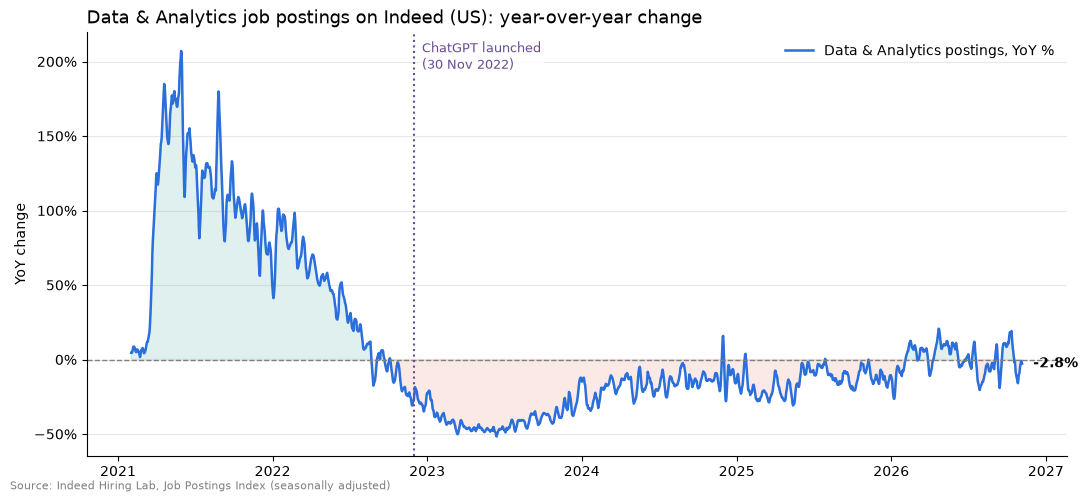

In [ ]:
"""
YoY change in Indeed job postings for the Data & Analytics sector.

Usage:
    1. Put this script in the same folder as job_postings_by_sector_US.csv
       (or change FILE_PATH below).
    2. Run:  python data_analytics_yoy.py
"""

import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick

FILE_PATH = "job_postings_by_sector_US.csv"
SECTOR_KEYWORD = "data"          # matches "Data & Analytics"

# ---------------------------------------------------------------
# 1. Read the data
# ---------------------------------------------------------------
df = pd.read_csv(FILE_PATH, parse_dates=["date"])

print("Columns:", list(df.columns))
print(df.head(), "\n")

# Find the sector column and the index-value column automatically,
# so the script works even if Indeed renames them slightly.
text_cols = df.select_dtypes(exclude=["number", "datetime"]).columns.tolist()
sector_col = max(text_cols, key=lambda c: df[c].nunique())   # column with most categories
value_col = [c for c in df.columns if "index" in c.lower()][0]

print(f"Sector column: {sector_col}")
print(f"Value column:  {value_col}")
print("Sectors available:", sorted(df[sector_col].unique()), "\n")

# ---------------------------------------------------------------
# 2. Filter to Data & Analytics
# ---------------------------------------------------------------
da = df[(df[sector_col] == "Data & Analytics") & (df["variable"] == "Data & Analytics")].copy()
print("Selected sector:", da[sector_col].unique())

# Some files hold several rows per date for one sector (e.g. a column
# that splits "total postings" vs "new postings"). Find any such column
# and keep a single row per date.
for col in da.select_dtypes(exclude=["number", "datetime"]).columns:
    if col == sector_col or da[col].nunique() <= 1:
        continue
    options = list(da[col].unique())
    keep = next((o for o in options if "total" in str(o).lower()), options[0])
    print(f"Column '{col}' splits rows into {options} -> keeping '{keep}'")
    da = da[da[col] == keep]

print("Rows per date:", da.groupby("date").size().max(), "(should be 1)\n")

da = da[["date", value_col]].sort_values("date").set_index("date")

# The index is a level where Feb 1, 2020 = 100. If your file instead
# stores "% change since Feb 2020" (values like -39.6), convert to a level.
if (da[value_col] < 0).any():
    da[value_col] = 100 + da[value_col]

# Sanity check against Indeed's 2026 report (~60.4 on 2025-10-31)
check_date = pd.Timestamp("2025-10-31")
if check_date in da.index:
    print(f"Index on {check_date.date()}: {da.loc[check_date, value_col]:.1f} "
          "(Indeed's report says ~60.4)\n")

# ---------------------------------------------------------------
# 3. Compute YoY % change
#    Compare each day with the same calendar day one year earlier.
# ---------------------------------------------------------------
last_year = da[value_col].copy()
last_year.index = last_year.index + pd.DateOffset(years=1)   # shift forward 1 year
last_year = last_year[~last_year.index.duplicated()]          # Feb 29 safety

da["value_last_year"] = last_year
da["yoy_pct"] = (da[value_col] / da["value_last_year"] - 1) * 100
yoy = da["yoy_pct"].dropna()

print("Latest YoY values:")
print(yoy.tail(5).round(1), "\n")

# Monthly average version (smoother, nicer for a portfolio)
yoy_monthly = yoy.resample("MS").mean()
print("Monthly average YoY, last 12 months:")
print(yoy_monthly.tail(12).round(1))

# ---------------------------------------------------------------
# 4. Line chart
# ---------------------------------------------------------------
fig, ax = plt.subplots(figsize=(11, 5))

ax.plot(yoy.index, yoy.values, color="#2a6fdb", linewidth=1.8,
        label="Data & Analytics postings, YoY %")
ax.axhline(0, color="grey", linewidth=1, linestyle="--")

# Shade growth vs decline
ax.fill_between(yoy.index, yoy.values, 0, where=yoy.values >= 0,
                color="#2a9d8f", alpha=0.15)
ax.fill_between(yoy.index, yoy.values, 0, where=yoy.values < 0,
                color="#e76f51", alpha=0.15)

# Mark the ChatGPT launch (Nov 30, 2022)
chatgpt_date = pd.Timestamp("2022-11-30")
ax.axvline(chatgpt_date, color="#6a4c93", linewidth=1.5, linestyle=":")
ax.annotate("ChatGPT launched\n(30 Nov 2022)",
            xy=(chatgpt_date, 1), xycoords=("data", "axes fraction"),
            xytext=(6, -6), textcoords="offset points",
            va="top", fontsize=9, color="#6a4c93",
            bbox=dict(facecolor="white", edgecolor="none", alpha=0.85, pad=2))

# Label the latest point
ax.annotate(f"{yoy.iloc[-1]:.1f}%",
            xy=(yoy.index[-1], yoy.iloc[-1]),
            xytext=(8, 0), textcoords="offset points",
            va="center", fontsize=10, fontweight="bold")

ax.set_title("Data & Analytics job postings on Indeed (US): year-over-year change",
             fontsize=13, loc="left")
ax.set_ylabel("YoY change")
ax.yaxis.set_major_formatter(mtick.PercentFormatter(decimals=0))
ax.spines[["top", "right"]].set_visible(False)
ax.grid(axis="y", alpha=0.3)
ax.legend(frameon=False, loc="upper right")

fig.text(0.01, 0.01, "Source: Indeed Hiring Lab, Job Postings Index (seasonally adjusted)",
         fontsize=8, color="grey")

plt.tight_layout()
plt.savefig("data_analytics_yoy.png", dpi=150)
plt.show()


In [6]:
df.head()

,date,jobcountry,indeed_job_postings_index,variable,display_name
0,2020-02-01,US,100.00,total postings,Accounting
1,2020-02-01,US,100.00,new postings,Accounting
2,2020-02-02,US,100.30,total postings,Accounting
3,2020-02-02,US,100.60,new postings,Accounting
4,2020-02-03,US,100.56,total postings,Accounting


In [7]:
df_analytics = df[df['display_name']=="Data & Analytics"]

In [8]:
df_analytics.head()

,date,jobcountry,indeed_job_postings_index,variable,display_name
123550,2020-02-01,US,100.00,total postings,Data & Analytics
123551,2020-02-01,US,100.00,new postings,Data & Analytics
123552,2020-02-02,US,99.97,total postings,Data & Analytics
123553,2020-02-02,US,99.95,new postings,Data & Analytics
123554,2020-02-03,US,99.84,total postings,Data & Analytics


In [10]:
df_analytics.describe()

,date,indeed_job_postings_index
count,4942,4942.000000
mean,2023-06-20 00:00:00,98.028138
min,2020-02-01 00:00:00,43.110000
25%,2021-10-10 06:00:00,67.707500
50%,2023-06-20 00:00:00,80.820000
75%,2025-02-26 18:00:00,120.120000
max,2026-11-06 00:00:00,203.400000
std,NaN,41.385529


In [15]:
df["display_name"].value_counts()

display_name
Accounting                                 4942
Administrative Assistance                  4942
Architecture                               4942
Arts & Entertainment                       4942
Aviation                                   4942
Personal Care & Home Health                4942
Childcare                                  4942
Construction                               4942
Customer Service                           4942
Driving                                    4942
Education & Instruction                    4942
Civil Engineering                          4942
Electrical Engineering                     4942
Industrial Engineering                     4942
Mechanical Engineering                     4942
Banking & Finance                          4942
Food Preparation & Service                 4942
Hospitality & Tourism                      4942
Human Resources                            4942
Installation & Maintenance                 4942
Insurance                  

In [13]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 232274 entries, 0 to 232273
Data columns (total 5 columns):
 #   Column                     Non-Null Count   Dtype         
---  ------                     --------------   -----         
 0   date                       232274 non-null  datetime64[us]
 1   jobcountry                 232274 non-null  str           
 2   indeed_job_postings_index  232274 non-null  float64       
 3   variable                   232274 non-null  str           
 4   display_name               232274 non-null  str           
dtypes: datetime64[us](1), float64(1), str(3)
memory usage: 8.9 MB


In [19]:
hypo_data = df[(df["display_name"].isin(["Software Development","Logistic Support","Driving","Childcare","Data & Analytics"])) & (df["variable"] == "new postings")]
hypo_data.head()

,date,jobcountry,indeed_job_postings_index,variable,display_name
29653,2020-02-01,US,100.00,new postings,Childcare
29655,2020-02-02,US,100.58,new postings,Childcare
29657,2020-02-03,US,100.99,new postings,Childcare
29659,2020-02-04,US,100.22,new postings,Childcare
29661,2020-02-05,US,99.53,new postings,Childcare


In [21]:
hypo_data["display_name"].value_counts()

display_name
Childcare               2471
Driving                 2471
Data & Analytics        2471
Software Development    2471
Logistic Support        2471
Name: count, dtype: int64

In [22]:
hypo_data["variable"].value_counts()

variable
new postings    12355
Name: count, dtype: int64

In [23]:
hypo_data1 = hypo_data.copy()

In [24]:
hypo_data1.head()

,date,jobcountry,indeed_job_postings_index,variable,display_name
29653,2020-02-01,US,100.00,new postings,Childcare
29655,2020-02-02,US,100.58,new postings,Childcare
29657,2020-02-03,US,100.99,new postings,Childcare
29659,2020-02-04,US,100.22,new postings,Childcare
29661,2020-02-05,US,99.53,new postings,Childcare


In [25]:
hypo_data1["date"] = hypo_data1["date"].dt.to_period("M")

In [26]:
hypo_data1.head()

,date,jobcountry,indeed_job_postings_index,variable,display_name
29653,2020-02,US,100.00,new postings,Childcare
29655,2020-02,US,100.58,new postings,Childcare
29657,2020-02,US,100.99,new postings,Childcare
29659,2020-02,US,100.22,new postings,Childcare
29661,2020-02,US,99.53,new postings,Childcare


In [27]:
hypo_data2 = hypo_data1.copy()

In [28]:
hypo_data2["jobcountry"].value_counts()

jobcountry
US    12355
Name: count, dtype: int64

In [31]:
hypo_data2 = hypo_data1.groupby(["date","display_name"])["indeed_job_postings_index"].mean().reset_index()

In [33]:
hypo_data2.head(20)

,date,display_name,indeed_job_postings_index
0,2020-02,Childcare,100.265172
1,2020-02,Data & Analytics,100.171034
2,2020-02,Driving,99.193103
3,2020-02,Logistic Support,98.841724
4,2020-02,Software Development,104.568276
5,2020-03,Childcare,64.947419
6,2020-03,Data & Analytics,85.557742
7,2020-03,Driving,89.179032
8,2020-03,Logistic Support,78.158065
9,2020-03,Software Development,99.566774


In [34]:
hypo_data2.shape

(410, 3)

In [40]:
hypo_data3 = hypo_data2.pivot_table(index="date", columns="display_name", values="indeed_job_postings_index")

In [57]:
hypo_data3 = hypo_data3.reset_index()

In [80]:
hypo_data4 = hypo_data3.copy()

In [81]:
hypo_data4["exposed_avg"] = hypo_data4[['Data & Analytics']].mean(axis=1)

In [82]:
hypo_data4.head()

display_name,date,Childcare,Data & Analytics,Driving,Logistic Support,Software Development,exposed_avg
0,2020-02,100.265172,100.171034,99.193103,98.841724,104.568276,100.171034
1,2020-03,64.947419,85.557742,89.179032,78.158065,99.566774,85.557742
2,2020-04,13.963000,47.398667,59.152667,33.305667,65.882667,47.398667
3,2020-05,36.600323,46.687742,76.815484,51.488387,61.459677,46.687742
4,2020-06,67.303667,53.133667,100.541333,71.766333,68.505333,53.133667


In [83]:
hypo_data4["low_avg"] = hypo_data4[['Childcare','Driving','Logistic Support']].mean(axis=1)

In [84]:
hypo_data4.head()

display_name,date,Childcare,Data & Analytics,Driving,Logistic Support,Software Development,exposed_avg,low_avg
0,2020-02,100.265172,100.171034,99.193103,98.841724,104.568276,100.171034,99.433333
1,2020-03,64.947419,85.557742,89.179032,78.158065,99.566774,85.557742,77.428172
2,2020-04,13.963000,47.398667,59.152667,33.305667,65.882667,47.398667,35.473778
3,2020-05,36.600323,46.687742,76.815484,51.488387,61.459677,46.687742,54.968065
4,2020-06,67.303667,53.133667,100.541333,71.766333,68.505333,53.133667,79.870444


In [85]:
hypo_data4["gap"] = hypo_data4["exposed_avg"] - hypo_data4["low_avg"]

In [86]:
hypo_data4.head()

display_name,date,Childcare,Data & Analytics,Driving,Logistic Support,Software Development,exposed_avg,low_avg,gap
0,2020-02,100.265172,100.171034,99.193103,98.841724,104.568276,100.171034,99.433333,0.737701
1,2020-03,64.947419,85.557742,89.179032,78.158065,99.566774,85.557742,77.428172,8.129570
2,2020-04,13.963000,47.398667,59.152667,33.305667,65.882667,47.398667,35.473778,11.924889
3,2020-05,36.600323,46.687742,76.815484,51.488387,61.459677,46.687742,54.968065,-8.280323
4,2020-06,67.303667,53.133667,100.541333,71.766333,68.505333,53.133667,79.870444,-26.736778


In [87]:
import numpy as np

In [88]:
hypo_data4["period"] = np.where(hypo_data4['date'] <= pd.Period("2022-11"), 'before', 'after')

In [89]:
hypo_data4.head()

display_name,date,Childcare,Data & Analytics,Driving,Logistic Support,Software Development,exposed_avg,low_avg,gap,period
0,2020-02,100.265172,100.171034,99.193103,98.841724,104.568276,100.171034,99.433333,0.737701,before
1,2020-03,64.947419,85.557742,89.179032,78.158065,99.566774,85.557742,77.428172,8.129570,before
2,2020-04,13.963000,47.398667,59.152667,33.305667,65.882667,47.398667,35.473778,11.924889,before
3,2020-05,36.600323,46.687742,76.815484,51.488387,61.459677,46.687742,54.968065,-8.280323,before
4,2020-06,67.303667,53.133667,100.541333,71.766333,68.505333,53.133667,79.870444,-26.736778,before


In [90]:
hypo_data4['period'].value_counts()

period
after     48
before    34
Name: count, dtype: int64

In [91]:
hypo_data4['date_ts'] = hypo_data4['date'].dt.to_timestamp()

In [92]:
hypo_data4.head()

display_name,date,Childcare,Data & Analytics,Driving,Logistic Support,Software Development,exposed_avg,low_avg,gap,period,date_ts
0,2020-02,100.265172,100.171034,99.193103,98.841724,104.568276,100.171034,99.433333,0.737701,before,2020-02-01
1,2020-03,64.947419,85.557742,89.179032,78.158065,99.566774,85.557742,77.428172,8.129570,before,2020-03-01
2,2020-04,13.963000,47.398667,59.152667,33.305667,65.882667,47.398667,35.473778,11.924889,before,2020-04-01
3,2020-05,36.600323,46.687742,76.815484,51.488387,61.459677,46.687742,54.968065,-8.280323,before,2020-05-01
4,2020-06,67.303667,53.133667,100.541333,71.766333,68.505333,53.133667,79.870444,-26.736778,before,2020-06-01


In [93]:
import matplotlib.pyplot as plt

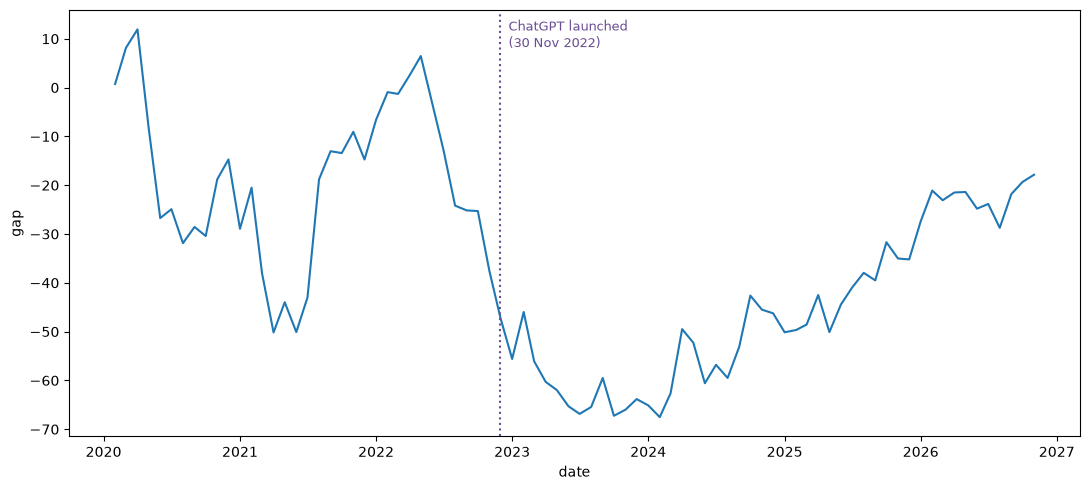

In [94]:
fig, ax = plt.subplots(figsize=(11, 5))

ax.plot(hypo_data4['date_ts'],hypo_data4['gap'])
ax.set_xlabel("date")
ax.set_ylabel("gap")

chatgpt_date = pd.Timestamp("2022-11-30")
ax.axvline(chatgpt_date, color="#6a4c93", linewidth=1.5, linestyle=":")
ax.annotate("ChatGPT launched\n(30 Nov 2022)",
            xy=(chatgpt_date, 1), xycoords=("data", "axes fraction"),
            xytext=(6, -6), textcoords="offset points",
            va="top", fontsize=9, color="#6a4c93",
            bbox=dict(facecolor="white", edgecolor="none", alpha=0.85, pad=2))
plt.tight_layout()
plt.show()

In [95]:
hypo_data4.head()

display_name,date,Childcare,Data & Analytics,Driving,Logistic Support,Software Development,exposed_avg,low_avg,gap,period,date_ts
0,2020-02,100.265172,100.171034,99.193103,98.841724,104.568276,100.171034,99.433333,0.737701,before,2020-02-01
1,2020-03,64.947419,85.557742,89.179032,78.158065,99.566774,85.557742,77.428172,8.129570,before,2020-03-01
2,2020-04,13.963000,47.398667,59.152667,33.305667,65.882667,47.398667,35.473778,11.924889,before,2020-04-01
3,2020-05,36.600323,46.687742,76.815484,51.488387,61.459677,46.687742,54.968065,-8.280323,before,2020-05-01
4,2020-06,67.303667,53.133667,100.541333,71.766333,68.505333,53.133667,79.870444,-26.736778,before,2020-06-01


In [100]:
hypo_data5 = hypo_data4[['date','Childcare','Data & Analytics','Driving','Logistic Support','exposed_avg','low_avg','gap','date_ts']]

In [101]:
hypo_data5.head()

display_name,date,Childcare,Data & Analytics,Driving,Logistic Support,exposed_avg,low_avg,gap,date_ts
0,2020-02,100.265172,100.171034,99.193103,98.841724,100.171034,99.433333,0.737701,2020-02-01
1,2020-03,64.947419,85.557742,89.179032,78.158065,85.557742,77.428172,8.129570,2020-03-01
2,2020-04,13.963000,47.398667,59.152667,33.305667,47.398667,35.473778,11.924889,2020-04-01
3,2020-05,36.600323,46.687742,76.815484,51.488387,46.687742,54.968065,-8.280323,2020-05-01
4,2020-06,67.303667,53.133667,100.541333,71.766333,53.133667,79.870444,-26.736778,2020-06-01


In [102]:
hypo_data5 = hypo_data5[hypo_data5['date'] >= '2021-01']

In [103]:
hypo_data5.head()

display_name,date,Childcare,Data & Analytics,Driving,Logistic Support,exposed_avg,low_avg,gap,date_ts
11,2021-01,110.500968,93.659032,144.795484,112.478710,93.659032,122.591720,-28.932688,2021-01-01
12,2021-02,112.450714,105.960714,141.599643,125.351071,105.960714,126.467143,-20.506429,2021-02-01
13,2021-03,127.821935,112.923548,181.780323,143.163226,112.923548,150.921828,-37.998280,2021-03-01
14,2021-04,147.060333,117.373000,192.080000,163.464333,117.373000,167.534889,-50.161889,2021-04-01
15,2021-05,150.631613,128.997742,192.346452,175.943548,128.997742,172.973871,-43.976129,2021-05-01


In [106]:
conditions = [
    hypo_data5['date'] <= '2022-04',
    (hypo_data5['date'] > '2022-04') & (hypo_data5['date'] <= '2024-12'),
    hypo_data5['date'] >= '2025-01'
]

choices = [
    'before',
    'turbulence',
    'longrun'
]

hypo_data5['period'] = np.select(condlist=conditions, choicelist=choices, default='F')

In [107]:
hypo_data5.head()

display_name,date,Childcare,Data & Analytics,Driving,Logistic Support,exposed_avg,low_avg,gap,date_ts,period
11,2021-01,110.500968,93.659032,144.795484,112.478710,93.659032,122.591720,-28.932688,2021-01-01,before
12,2021-02,112.450714,105.960714,141.599643,125.351071,105.960714,126.467143,-20.506429,2021-02-01,before
13,2021-03,127.821935,112.923548,181.780323,143.163226,112.923548,150.921828,-37.998280,2021-03-01,before
14,2021-04,147.060333,117.373000,192.080000,163.464333,117.373000,167.534889,-50.161889,2021-04-01,before
15,2021-05,150.631613,128.997742,192.346452,175.943548,128.997742,172.973871,-43.976129,2021-05-01,before


In [108]:
hypo_data5['period'].value_counts()

period
turbulence    32
longrun       23
before        16
Name: count, dtype: int64

In [109]:
gap_before = hypo_data5.loc[hypo_data5['period']=='before', 'gap']

In [110]:
gap_before

11   -28.932688
12   -20.506429
13   -37.998280
14   -50.161889
15   -43.976129
16   -50.088000
17   -43.011720
18   -18.808280
19   -13.034556
20   -13.417849
21    -9.060222
22   -14.740108
23    -6.596989
24    -0.928810
25    -1.296452
26     2.512556
Name: gap, dtype: float64

In [111]:
gap_before.mean()

np.float64(-21.87786523937532)

In [112]:
gap_before = float(gap_before.mean())

In [113]:
gap_before

-21.87786523937532

In [114]:
gap_longrun = hypo_data5.loc[hypo_data5['period']=='longrun', 'gap']

In [115]:
gap_longrun = float(gap_longrun.mean())

In [116]:
gap_longrun

-32.89425473630312

In [117]:
from scipy import stats

In [118]:
gap_before = hypo_data5.loc[hypo_data5['period']=='before', 'gap']
gap_longrun = hypo_data5.loc[hypo_data5['period']=='longrun', 'gap']

In [128]:
result = stats.ttest_ind(gap_longrun, gap_before, equal_var=False, alternative='less')

In [129]:
result

TtestResult(statistic=np.float64(-2.168189342103885), pvalue=np.float64(0.02040777111292027), df=np.float64(22.835434278135647))

In [130]:
t = result.statistic
p = result.pvalue
dfm = result.df

In [131]:
ci = result.confidence_interval(confidence_level=0.95)

In [132]:
ci

ConfidenceInterval(low=np.float64(-inf), high=np.float64(-2.3057186459532026))

In [133]:
low = ci.low
high = ci.high

In [134]:
print(f"t:{t}")
print(f"p-value:{p}")
print(f"degree of freedom:{dfm}")
print(f"CI low:{low}")
print(f"CI high:{high}")

print(f"difference between mean gap_longrun and mean gap_before:{-32.89425473630312-(-21.87786523937532)}")

t:-2.168189342103885
p-value:0.02040777111292027
degree of freedom:22.835434278135647
CI low:-inf
CI high:-2.3057186459532026
difference between mean gap_longrun and mean gap_before:-11.016389496927797
